# Más neuronas.

Como vimos en el primer ejemplo. La función $f(x)=\sqrt{x}$ es más complicada de ajustar por su comportamiento. Entonces más tiempo no garantizará mejores resultados. Entonces podemos intentar aumentar el número de neuronas. Entonces nuestro modelo tendría esta forma 

$$
\mathfrak{m}(x,\Theta) = \sum_{n=1}^N c^n\sigma(w^nx+b^n),\Theta = \{(c^n,w^n,b^n)\}_{n=1}^N.
$$

## Transformación.

Retomando la forma de Red tendriamos un vector 
$$
\left[\begin{array}{c}
c^{1}\sigma\left(w^{1}x+b^{1}\right)\\
\vdots\\
c^{N}\sigma\left(w^{N}x+b^{N}\right)
\end{array}\right]
$$

Replicando el comportamiento de Python podemos ver esto como 
$$
\mathbf{c}\sigma\left(x\mathbf{w}+\mathbf{b}\right).\text{sum}()
$$
donde $\mathbf{w},\mathbf{c},\mathbf{b}$ son vectores. 


In [65]:
import numpy as np
from neuralnetworks.nn import descent_gradent, sigmoid


def model(t, Theta):
    Theta = Theta.reshape((NEURONS, 3))
    C = Theta[:,0]
    W = Theta[:,1]
    B = Theta[:,2]
    x = W * t + B
    y = C * sigmoid(x)
    return y.sum()

def mse_nn(y, x, func, pars):
    pred = [func(t, pars) for t in x]
    diff = (y - pred) ** 2
    error = diff.mean()
    return error

NEURONS = 10
Theta = np.zeros((NEURONS, 3))
Theta0 = np.ones((NEURONS, 3))
theta0 = Theta0.flatten()


train_x = np.linspace(0, 50, 20)
train_y = np.sqrt(train_x)

def mse(pars, func=model, y=train_y, x=train_x):
    return mse_nn(y, x, func, pars)


fitpar = descent_gradent(mse, theta0, 0.001, lr = 0.01)

fitpar


0 0.32279183520579147
1000 0.0015549634930893457
2000 0.0037465836683836596
3000 0.0017724093964853274
Error 0.1934666589390414


array([ 0.69170511,  0.08377991, -1.05602192,  0.69170511,  0.08377991,
       -1.05602192,  0.69170511,  0.08377991, -1.05602192,  0.69170511,
        0.08377991, -1.05602192,  0.69170511,  0.08377991, -1.05602192,
        0.69170511,  0.08377991, -1.05602192,  0.69170511,  0.08377991,
       -1.05602192,  0.69170511,  0.08377991, -1.05602192,  0.69170511,
        0.08377991, -1.05602192,  0.69170511,  0.08377991, -1.05602192])

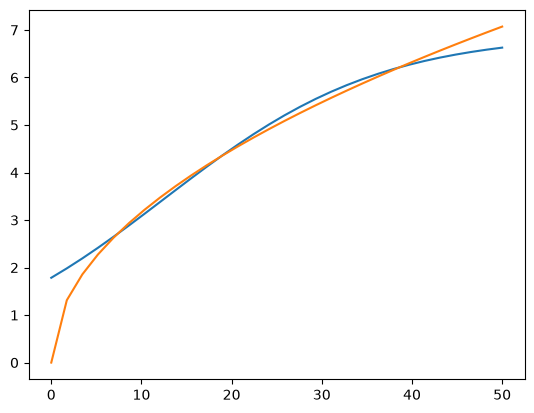

In [66]:
import matplotlib.pyplot as plt

test_x = np.linspace(0, 50, 30)
pred = np.array([model(t, fitpar) for t in test_x])

plt.plot(test_x, pred)
plt.plot(test_x, np.sqrt(test_x))
